# Fooling images por ascenso de gradiente (2026-10-17)

Réplica de la sección 3.9 de Nguyen, Yosinski & Clune (2015), *Deep Neural Networks are Easily Fooled: High Confidence Predictions for Unrecognizable Images* (CVPR 2015, [arXiv:1412.1897](https://arxiv.org/abs/1412.1897)).

**Pregunta:** ¿se puede optimizar una imagen que parece ruido pero que el modelo clasifica con casi total certeza como una clase de animal? Y, para la tesis: ¿qué tan fácil es esto en el modelo penalizado frente al modelo base?

**Método del paper (sec. 3.9):** gradiente de la probabilidad posterior (salida softmax) de una clase respecto a los **píxeles de entrada**, y ascenso de gradiente. Se parte de la imagen media del dataset más ruido gaussiano pequeño (para romper la simetría) y se continúa hasta que la confianza de la clase objetivo llega a 99.99%.

**Modelos** (mismo config, AwA2, semilla 0): `unconstrained` (base), `constrained` (producto punto entre cabezas), `constrained_rank` (producto punto + anti-colapso). No se incluyen las variantes `reward_similarity`.

**Diferencias respecto al paper (a tener presentes al citar resultados):**
- Modelo: ViT pequeño sobre AwA2 de 32×32 y 50 clases, no AlexNet sobre ImageNet.
- Se maximiza el **log-softmax** de la clase objetivo con Adam, en vez de la probabilidad con ascenso simple: mismo argmax, pero el gradiente no se desvanece cuando la probabilidad satura.
- Dos variantes de dominio: `clamp=True` mantiene los píxeles en el rango válido de imagen ([-1, 1] tras la normalización del dataset) y `clamp=False` los deja libres, como en el paper.
- Solo ascenso de gradiente; no se replican los algoritmos evolutivos (MAP-Elites, CPPN).

In [1]:
import json
import sys
from pathlib import Path

project_root = Path.cwd().resolve().parents[1]
print(f"Project root: {project_root}")
sys.path.append(str(project_root))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from modules.model import ViTForClassfication
from modules.datasets import AwA2Dataset
from modules.figures import save_fig

torch.manual_seed(0)
device = torch.device("cpu")

EXPERIMENTS_DIR = project_root / "experimentation" / "experiments"
OUTPUT_DIR = EXPERIMENTS_DIR / "17102026_fooling_images"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODELS = {
    "unconstrained": "vit-15-AwA2",
    "constrained": "vit-15-constrained-AwA2",
    "constrained_rank": "vit-15-constrained_rank-AwA2",
}

THRESHOLD = 0.9999   # confianza objetivo del paper (99.99%)
MAX_STEPS = 2000     # presupuesto de pasos de gradiente por imagen
LR = 0.02            # paso de Adam sobre los píxeles
N_INITS = 3          # inicializaciones (ruido) distintas por clase
INIT_NOISE = 0.01    # desviación del ruido gaussiano sobre la imagen media

Project root: /Users/valefeve/Projects/interpretability of neural networks/interpretable-transformers


## 1. Modelos y datos

In [2]:
def load_model(name):
    exp_dir = EXPERIMENTS_DIR / name
    with open(exp_dir / "config.json") as f:
        config = json.load(f)
    with open(exp_dir / "metrics.json") as f:
        metrics = json.load(f)
    model = ViTForClassfication(config)
    model.load_state_dict(torch.load(exp_dir / "model_final.pt", map_location="cpu"))
    model.eval()
    for p in model.parameters():
        p.requires_grad_(False)   # solo se optimiza la imagen
    return model, config, metrics


models = {key: load_model(name) for key, name in MODELS.items()}
config = models["unconstrained"][1]
assert all(m[1] == config for m in models.values()), "Los modelos deben tener la misma arquitectura"
for key, (_, _, metrics) in models.items():
    print(f"{key:>16} ({MODELS[key]}): accuracy = {metrics['accuracy']:.4f}")

dataset = AwA2Dataset(image_size=32, root=str(project_root / "data" / "awa2"))
_, testloader, classes = dataset.get_loaders(batch_size=256)
K = dataset.n_classes
print(f"{K} clases")

# Muestra de test (semilla fija; el test viene ordenado por clase) para la imagen media y la confianza en imágenes reales
idx = torch.randperm(len(dataset.testset), generator=torch.Generator().manual_seed(0))[:1000].tolist()
real_images, real_labels = dataset.get_samples_from_indices(idx, device="cpu", set="test")
mean_image = real_images.mean(dim=0, keepdim=True)    # (1, 3, 32, 32), en el espacio normalizado del dataset
print("imagen media:", tuple(mean_image.shape), f"rango [{mean_image.min():.2f}, {mean_image.max():.2f}]")

   unconstrained (vit-15-AwA2): accuracy = 0.2971
     constrained (vit-15-constrained-AwA2): accuracy = 0.2879
constrained_rank (vit-15-constrained_rank-AwA2): accuracy = 0.2973


50 clases
imagen media: (1, 3, 32, 32) rango [-0.29, 0.02]


## 2. Referencia: confianza del modelo en imágenes reales

Para dimensionar qué significa "99.99%" en estos modelos: con ~30% de accuracy en 50 clases, la confianza típica en imágenes **reales** es baja. Que una imagen de ruido alcance 99.99% es, por tanto, mucho más certeza que la que el modelo da a una foto real.

In [3]:
@torch.no_grad()
def real_confidence(model):
    probs = F.softmax(model(real_images)[0], dim=-1)
    top = probs.max(dim=-1)
    return top.values.mean().item(), (top.indices == real_labels).float().mean().item(), probs.max(dim=-1).values.quantile(0.99).item()

ref_rows = {}
for key, (model, _, _) in models.items():
    conf, acc, q99 = real_confidence(model)
    ref_rows[key] = {"confianza media (imágenes reales)": conf, "accuracy (muestra)": acc, "confianza p99 (imágenes reales)": q99}
ref_df = pd.DataFrame(ref_rows).T
print(ref_df.round(3).to_string())

                  confianza media (imágenes reales)  accuracy (muestra)  confianza p99 (imágenes reales)
unconstrained                                 0.329               0.323                            0.893
constrained                                   0.357               0.300                            0.922
constrained_rank                              0.359               0.318                            0.930


## 3. La función: ascenso de gradiente sobre los píxeles

Se optimizan a la vez todas las imágenes (una por clase y por inicialización); no hay interacción entre ellas porque el modelo está en modo `eval` y la normalización es por token. Cada imagen deja de actualizarse en cuanto su clase objetivo alcanza `THRESHOLD`, y se guarda en ese paso. Si nunca lo alcanza, se devuelve la imagen del último paso y cuenta como "no engañada".

In [4]:
def fool(model, targets, x0, clamp, threshold=THRESHOLD, max_steps=MAX_STEPS, lr=LR):
    x = x0.clone().requires_grad_(True)
    opt = torch.optim.Adam([x], lr=lr)
    n = len(targets)
    done = torch.zeros(n, dtype=torch.bool)
    steps = torch.full((n,), max_steps)
    result = x.detach().clone()
    traj = []                                    # probabilidad mediana de la clase objetivo por paso
    for step in range(max_steps):
        logp = F.log_softmax(model(x)[0], dim=-1)
        logp_t = logp.gather(1, targets[:, None])[:, 0]
        prob = logp_t.detach().exp()
        traj.append(prob.median().item())
        newly = (~done) & (prob >= threshold)
        if newly.any():
            steps[newly] = step
            result[newly] = x.detach()[newly]
            done |= newly
        if done.all():
            break
        loss = -(logp_t * (~done).float()).sum()
        opt.zero_grad()
        loss.backward()
        opt.step()
        if clamp:
            with torch.no_grad():
                x.clamp_(-1, 1)
    result[~done] = x.detach()[~done]
    return result, steps, done, traj


# Mismos objetivos e inicializaciones para los tres modelos (comparación justa)
targets = torch.arange(K).repeat(N_INITS)
g = torch.Generator().manual_seed(1)
x0 = (mean_image + INIT_NOISE * torch.randn(len(targets), 3, 32, 32, generator=g)).clamp(-1, 1)
print("imágenes por corrida:", len(targets))

imágenes por corrida: 150


## 4. Correr los tres modelos (con y sin restricción de rango de píxeles)

In [5]:
results = {}   # (clamp, key) -> dict
for clamp in (True, False):
    for key, (model, _, _) in models.items():
        x, steps, done, traj = fool(model, targets, x0, clamp)
        with torch.no_grad():
            probs = F.softmax(model(x)[0], dim=-1)
        p_t = probs.gather(1, targets[:, None])[:, 0]
        results[(clamp, key)] = dict(x=x, steps=steps, done=done, traj=traj, p_target=p_t)
        print(f"clamp={clamp!s:5} {key:>16}: engañadas {int(done.sum())}/{len(targets)} | "
              f"pasos mediana (engañadas) {steps[done].float().median().item() if done.any() else float('nan'):.0f} | "
              f"p objetivo media {p_t.mean().item():.4f}")

clamp=True     unconstrained: engañadas 66/150 | pasos mediana (engañadas) 720 | p objetivo media 0.9997


clamp=True       constrained: engañadas 79/150 | pasos mediana (engañadas) 983 | p objetivo media 0.9995


clamp=True  constrained_rank: engañadas 49/150 | pasos mediana (engañadas) 750 | p objetivo media 0.9992


clamp=False    unconstrained: engañadas 66/150 | pasos mediana (engañadas) 720 | p objetivo media 0.9997


clamp=False      constrained: engañadas 79/150 | pasos mediana (engañadas) 983 | p objetivo media 0.9996


clamp=False constrained_rank: engañadas 52/150 | pasos mediana (engañadas) 810 | p objetivo media 0.9994


## 5. Tabla resumen

- **% engañadas:** fracción de (clase, inicialización) que llega a `THRESHOLD` dentro del presupuesto.
- **Pasos (mediana):** pasos de gradiente que necesita; más pasos = más difícil de engañar.
- **Distancia a la imagen inicial:** RMS por píxel de `x − x0` en el espacio normalizado ([-1, 1]); qué tanto hubo que alejarse de la imagen media.
- **Total variation:** rugosidad espacial de la imagen final (alta = más parecida a ruido blanco).

In [6]:
def total_variation(x):
    dh = (x[:, :, 1:, :] - x[:, :, :-1, :]).abs().mean(dim=(1, 2, 3))
    dw = (x[:, :, :, 1:] - x[:, :, :, :-1]).abs().mean(dim=(1, 2, 3))
    return (dh + dw) / 2

rows = []
for (clamp, key), r in results.items():
    done = r["done"]
    rows.append({
        "clamp": clamp, "modelo": key,
        "% engañadas": 100 * done.float().mean().item(),
        "pasos (mediana, engañadas)": r["steps"][done].float().median().item() if done.any() else np.nan,
        "p objetivo (media, todas)": r["p_target"].mean().item(),
        "distancia a x0 (RMS)": (r["x"] - x0).pow(2).mean(dim=(1, 2, 3)).sqrt().mean().item(),
        "total variation": total_variation(r["x"]).mean().item(),
    })
summary = pd.DataFrame(rows).set_index(["clamp", "modelo"])
print(summary.round(3).to_string())
summary.to_csv(OUTPUT_DIR / "fooling_summary.csv")
ref_df.to_csv(OUTPUT_DIR / "real_image_confidence.csv")

                        % engañadas  pasos (mediana, engañadas)  p objetivo (media, todas)  distancia a x0 (RMS)  total variation
clamp modelo                                                                                                                     
True  unconstrained          44.000                       720.0                      1.000                 0.228            0.172
      constrained            52.667                       983.0                      0.999                 0.227            0.173
      constrained_rank       32.667                       750.0                      0.999                 0.236            0.177
False unconstrained          44.000                       720.0                      1.000                 0.234            0.174
      constrained            52.667                       983.0                      1.000                 0.233            0.175
      constrained_rank       34.667                       810.0                      0.999

## 6. Velocidad: probabilidad de la clase objetivo por paso

Mediana, entre todas las imágenes, de la probabilidad de la clase objetivo a lo largo de la optimización. Una curva que sube más lento indica un modelo más difícil de engañar.

guardado: experimentation/experiments/17102026_fooling_images/fooling_trajectory.png


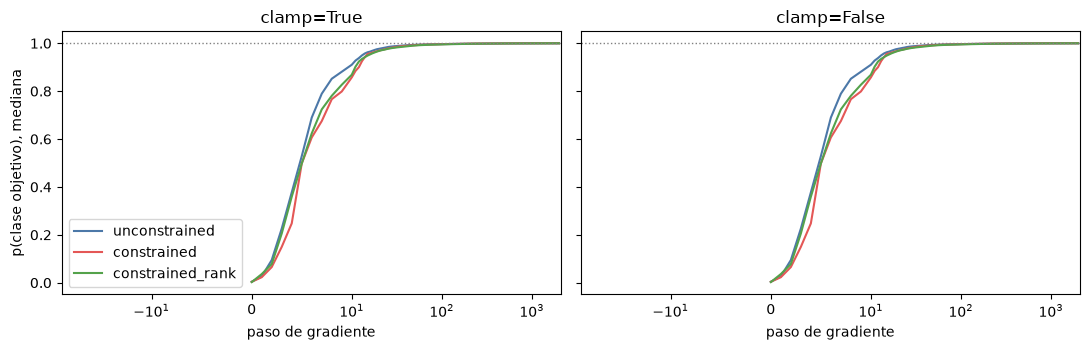

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
colors = {"unconstrained": "#4C78A8", "constrained": "#E45756", "constrained_rank": "#54A24B"}
for ax, clamp in zip(axes, (True, False)):
    for key in MODELS:
        ax.plot(results[(clamp, key)]["traj"], label=key, color=colors[key])
    ax.axhline(THRESHOLD, color="gray", ls=":", lw=1)
    ax.set_xscale("symlog", linthresh=10)
    ax.set_xlabel("paso de gradiente")
    ax.set_title(f"clamp={clamp}")
axes[0].set_ylabel("p(clase objetivo), mediana")
axes[0].legend()
fig.tight_layout()
save_fig(fig, "fooling_trajectory", OUTPUT_DIR, project_root=project_root)
plt.show()

## 7. Las imágenes (inicialización 0, una por clase)

guardado: experimentation/experiments/17102026_fooling_images/fooling_grid_vit-15-AwA2_clampTrue.png


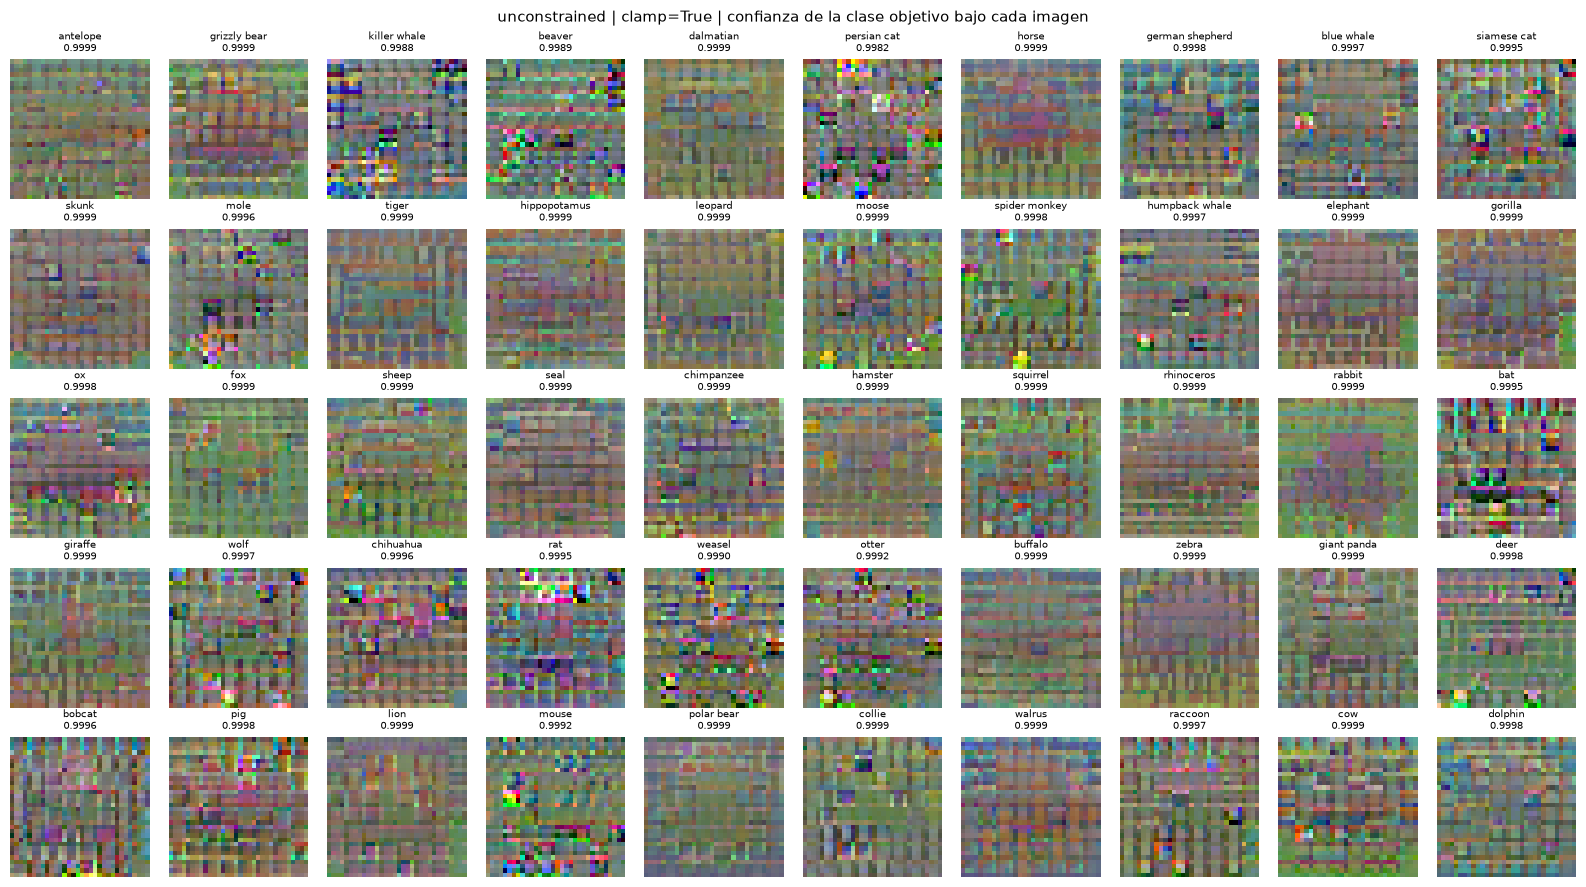

guardado: experimentation/experiments/17102026_fooling_images/fooling_grid_vit-15-constrained-AwA2_clampTrue.png


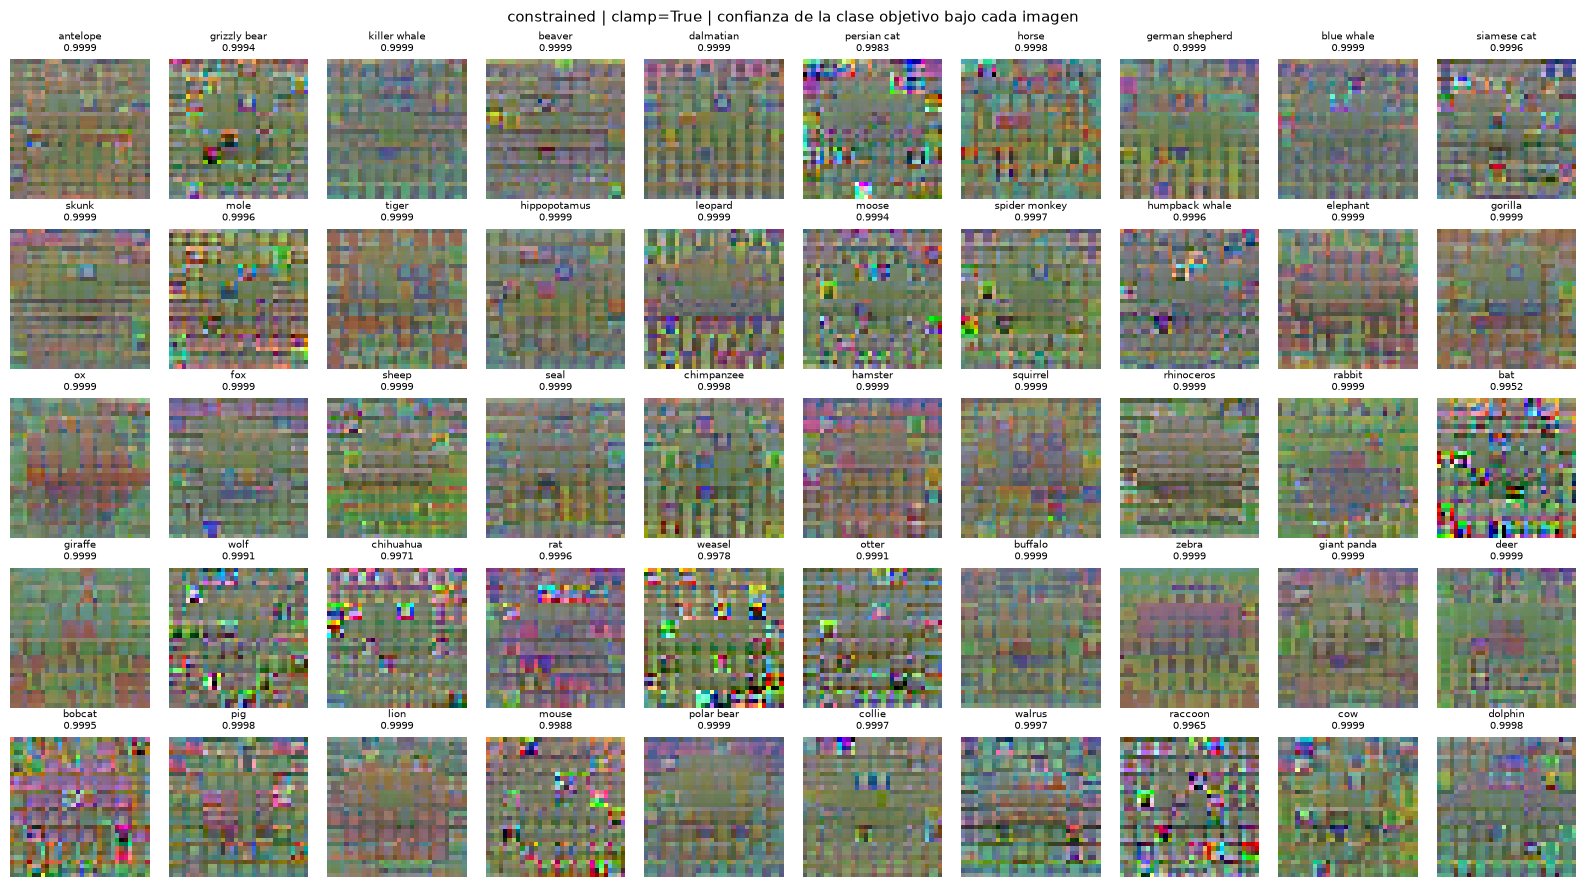

guardado: experimentation/experiments/17102026_fooling_images/fooling_grid_vit-15-constrained_rank-AwA2_clampTrue.png


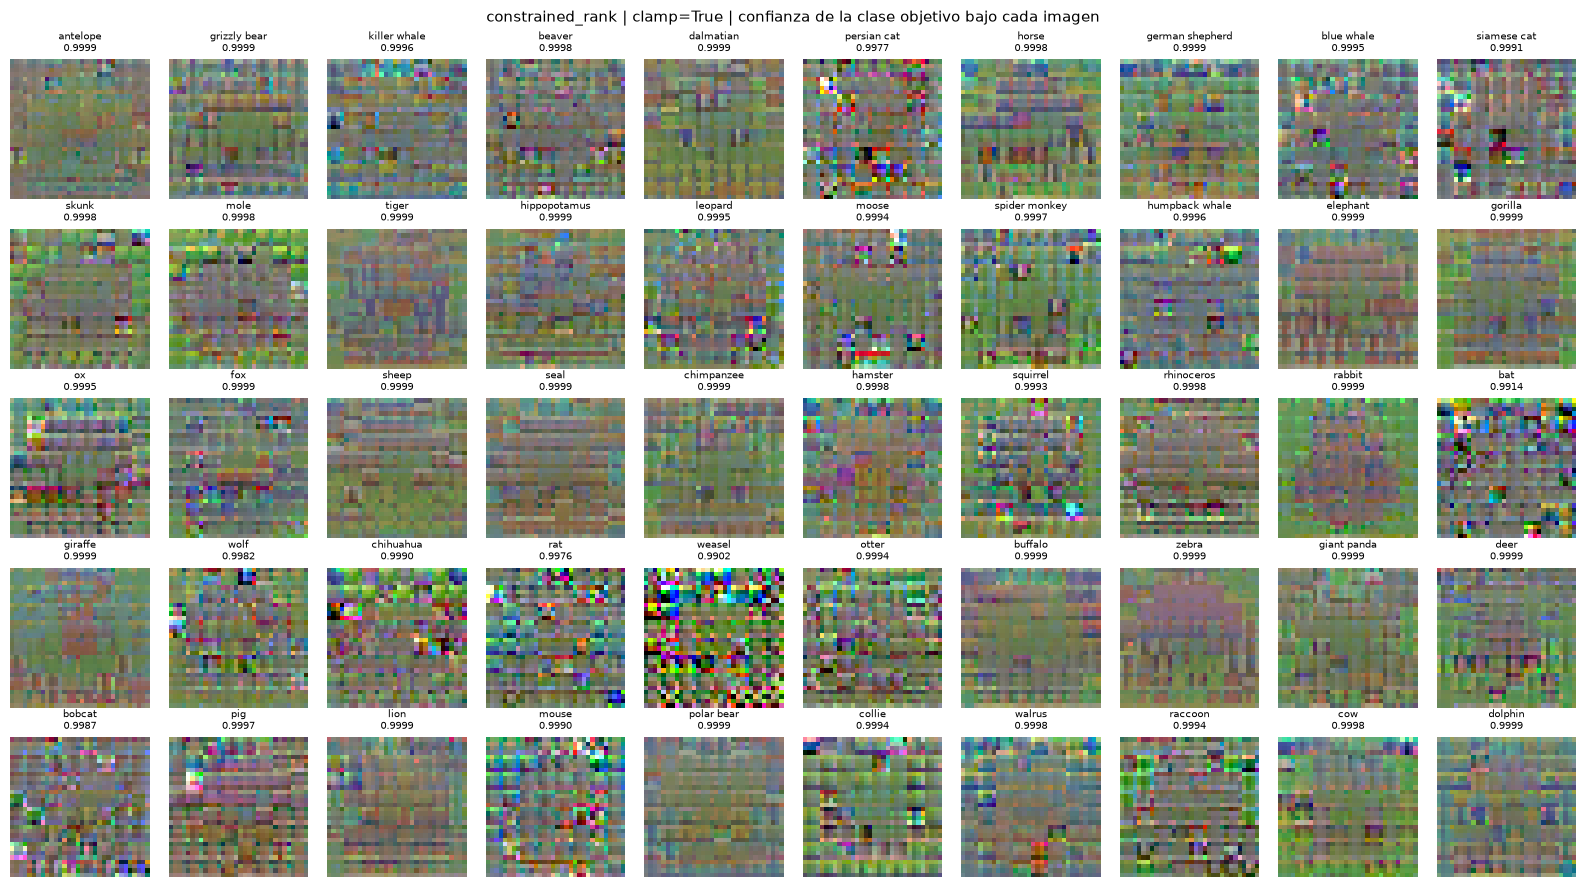

In [8]:
def show_grid(key, clamp, init=0):
    r = results[(clamp, key)]
    sl = slice(init * K, (init + 1) * K)
    imgs = (r["x"][sl] * 0.5 + 0.5).clamp(0, 1)        # al rango de imagen para mostrar
    probs = r["p_target"][sl]
    fig, axes = plt.subplots(5, 10, figsize=(16, 9))
    for c, ax in enumerate(axes.ravel()):
        ax.imshow(imgs[c].permute(1, 2, 0).numpy())
        ax.set_title(f"{classes[c]}\n{probs[c]:.4f}", fontsize=7)
        ax.axis("off")
    fig.suptitle(f"{key} | clamp={clamp} | confianza de la clase objetivo bajo cada imagen", fontsize=11)
    fig.tight_layout()
    save_fig(fig, "fooling_grid", OUTPUT_DIR, tag=f"{MODELS[key]}_clamp{clamp}", project_root=project_root)
    plt.show()

for key in MODELS:
    show_grid(key, clamp=True)

## 8. Transferencia entre modelos (sec. 3.5 del paper)

El paper encuentra que muchas imágenes que engañan a una red también engañan a otra con la misma arquitectura y otra inicialización. Aquí: imágenes que engañaron al modelo de la fila (clamp=True), evaluadas en el modelo de la columna. Se reporta el porcentaje en que el otro modelo también predice la clase objetivo con ≥ 0.99.

In [9]:
tr = pd.DataFrame(index=list(MODELS), columns=list(MODELS), dtype=float)
tr_p = pd.DataFrame(index=list(MODELS), columns=list(MODELS), dtype=float)
for src in MODELS:
    r = results[(True, src)]
    ok = r["done"]
    for dst, (model, _, _) in models.items():
        with torch.no_grad():
            probs = F.softmax(model(r["x"][ok])[0], dim=-1)
        p_t = probs.gather(1, targets[ok][:, None])[:, 0]
        hit = (probs.argmax(-1) == targets[ok]) & (p_t >= 0.99)
        tr.loc[src, dst] = 100 * hit.float().mean().item()
        tr_p.loc[src, dst] = p_t.mean().item()
print("% de imágenes que engañan también al modelo de la columna (p>=0.99, argmax = objetivo):")
print(tr.round(1).to_string())
print("\np media de la clase objetivo en el modelo de la columna:")
print(tr_p.round(3).to_string())
tr.to_csv(OUTPUT_DIR / "fooling_transfer_pct.csv")
tr_p.to_csv(OUTPUT_DIR / "fooling_transfer_mean_p.csv")
torch.save({f"{k[1]}_clamp{k[0]}": v["x"] for k, v in results.items()}, OUTPUT_DIR / "fooling_images.pt")

% de imágenes que engañan también al modelo de la columna (p>=0.99, argmax = objetivo):
                  unconstrained  constrained  constrained_rank
unconstrained             100.0          3.0               0.0
constrained                 0.0        100.0               0.0
constrained_rank            0.0          6.1             100.0

p media de la clase objetivo en el modelo de la columna:
                  unconstrained  constrained  constrained_rank
unconstrained             1.000        0.498             0.479
constrained               0.281        1.000             0.401
constrained_rank          0.391        0.637             1.000


## Cómo leer los resultados

- Si el modelo penalizado necesita **más pasos** o engaña a **menos** imágenes dentro del presupuesto, es más difícil de engañar por este método. Si no, la penalización no reduce este punto ciego.
- Una confianza de 99.99% sobre ruido, cuando en imágenes reales la confianza es mucho menor, es el fenómeno del paper (modelos discriminativos asignan regiones enormes del espacio de imágenes a una clase).
- Con una sola semilla de entrenamiento por variante, las diferencias entre modelos pueden deberse a la inicialización; para afirmarlas hay que repetir con las semillas 1 y 2 (`vit-15-<variante>-s1-AwA2`, `-s2-`).